In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the election dataset
df = pd.read_csv("US_Election_dataset_v1.csv")

# Display the dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3143, 35)


,Unnamed: 0,county,state,2020 Democrat vote raw,2020 Democrat vote %,2020 Republican vote raw,2020 Republican vote %,2020 other vote raw,2020 other vote %,Population with less than 9th grade education,...,NH-American Indian and Alaska Native percentage,NH-Asian percentage,NH-Native Hawaiian and Other Pacific Islander percentage,NH-Some Other Race percentage,NH-Two or More Races percentage,"Percentage engaged in Management, business, science, and arts occupations",Percentage engaged in Service Occupations,Percentage engaged in Sales and Office,Percentage engaged in Resources and Construction,Percentage engaged in Transportation
0,"Autauga County, Alabama",Autauga County,Alabama,7503,27.02,19838,71.44,429,1.54,1.70%,...,0.31,1.48,0.04,0.31,4.23,36.39,14.24,22.02,9.99,17.36
1,"Baldwin County, Alabama",Baldwin County,Alabama,24578,22.41,83544,76.17,1557,1.42,2.00%,...,0.56,0.88,0.05,0.33,4.47,35.62,17.14,24.20,9.91,13.13
2,"Barbour County, Alabama",Barbour County,Alabama,4816,45.79,5622,53.45,80,0.76,7.30%,...,0.23,0.41,0.00,0.25,2.19,27.73,20.16,19.49,12.53,20.09
3,"Bibb County, Alabama",Bibb County,Alabama,1986,20.70,7525,78.43,84,0.88,6.40%,...,0.17,0.12,0.04,0.21,2.69,22.22,15.32,20.57,16.43,25.47
4,"Blount County, Alabama",Blount County,Alabama,2640,9.57,24711,89.57,237,0.86,7.10%,...,0.32,0.29,0.02,0.17,3.89,26.75,12.98,22.73,15.81,21.73


# 2. Data Cleaning and Preparation

Before training the ANN, the dataset must be cleaned to ensure the information is consistent and suitable for machine learning.

The group's preprocessing code checks for duplicate counties, converts numerical values into the correct format, identifies missing values, and recalculates voting percentages using the raw election results.

This helps identify potential data quality issues before the dataset is used for modeling.

In [102]:
import pandas as pd
import sys
from pathlib import Path

# Find David's cleaning file
project_folder = Path("US_Election.py").resolve().parent
sys.path.insert(0, str(project_folder))

# Import David's cleaning function
from US_Election import clean_data

# Clean the dataset
df = clean_data("US_Election_dataset_v1.csv")

print("Cleaned dataset shape:", df.shape)
display(df.head())


Dataset Cleaning Results
Original: 3,143 rows, 35 columns
Cleaned: 3,143 rows, 34 columns
Duplicate counties: 0

Missing values:
Median income (dollars)    1

Voting percentage corrections:
Dona Ana County, NewMexico: 36.69 -> 39.69

Counties with more votes than population:
Haines Borough, Alaska
Loving County, Texas

First 5 rows (selected columns):
        county   state  Median income (dollars)  2020 Republican vote %
Autauga County Alabama                  68315.0                   71.44
Baldwin County Alabama                  71039.0                   76.17
Barbour County Alabama                  39712.0                   53.45
   Bibb County Alabama                  50669.0                   78.43
 Blount County Alabama                  57440.0                   89.57
Cleaned dataset shape: (3143, 34)


,county,state,2020 Democrat vote raw,2020 Democrat vote %,2020 Republican vote raw,2020 Republican vote %,2020 other vote raw,2020 other vote %,Population with less than 9th grade education,"Population with 9th to 12th grade education, no diploma",...,NH-American Indian and Alaska Native percentage,NH-Asian percentage,NH-Native Hawaiian and Other Pacific Islander percentage,NH-Some Other Race percentage,NH-Two or More Races percentage,"Percentage engaged in Management, business, science, and arts occupations",Percentage engaged in Service Occupations,Percentage engaged in Sales and Office,Percentage engaged in Resources and Construction,Percentage engaged in Transportation
0,Autauga County,Alabama,7503,27.02,19838,71.44,429,1.54,1.7,7.9,...,0.31,1.48,0.04,0.31,4.23,36.39,14.24,22.02,9.99,17.36
1,Baldwin County,Alabama,24578,22.41,83544,76.17,1557,1.42,2.0,6.4,...,0.56,0.88,0.05,0.33,4.47,35.62,17.14,24.20,9.91,13.13
2,Barbour County,Alabama,4816,45.79,5622,53.45,80,0.76,7.3,16.2,...,0.23,0.41,0.00,0.25,2.19,27.73,20.16,19.49,12.53,20.09
3,Bibb County,Alabama,1986,20.70,7525,78.43,84,0.88,6.4,14.7,...,0.17,0.12,0.04,0.21,2.69,22.22,15.32,20.57,16.43,25.47
4,Blount County,Alabama,2640,9.57,24711,89.57,237,0.86,7.1,11.1,...,0.32,0.29,0.02,0.17,3.89,26.75,12.98,22.73,15.81,21.73


# 3. Create the Target Variable

The ANN will perform binary classification to predict which major political party received more votes in each county during the 2020 presidential election.

Since the dataset does not directly identify the winning party, a new target variable called `winner_2020` is created by comparing Democratic and Republican vote counts.

- *0 = Republican*
- *1 = Democrat*

This target represents the historical election outcome that the ANN will attempt to predict.

In [103]:
# Create a target column using the 2020 election results
df["winner_2020"] = np.where(
    df["2020 Democrat vote raw"] > df["2020 Republican vote raw"],
    1, 0
)

# Display the results
display(df[[
    "county",
    "state",
    "2020 Democrat vote raw",
    "2020 Republican vote raw",
    "winner_2020"
]].head())

,county,state,2020 Democrat vote raw,2020 Republican vote raw,winner_2020
0,Autauga County,Alabama,7503,19838,0
1,Baldwin County,Alabama,24578,83544,0
2,Barbour County,Alabama,4816,5622,0
3,Bibb County,Alabama,1986,7525,0
4,Blount County,Alabama,2640,24711,0


# 4. Select Input Features (X) and Target (y)

The dataset is separated into the input features (X) and the target variable (y).

**X (Input Features):** Socioeconomic and demographic characteristics such as median income, education, population, and racial composition.

**y (Target Variable):** The 2020 election winner, represented as either Republican (0) or Democrat (1).

County names, state names, and 2020 election vote counts and percentages are excluded from the input features. This prevents data leakage, which occurs when the model receives information that directly reveals the answer it is supposed to predict.

The goal is to determine whether socioeconomic and demographic patterns are associated with county-level voting outcomes.

In [104]:
# Select socioeconomic and demographic features
# Exclude county names, states, and election results

X = df.drop(columns=[
    "county",
    "state",
    "winner_2020",
    "Unnamed: 0",
    "2020 Democrat vote raw",
    "2020 Democrat vote %",
    "2020 Republican vote raw",
    "2020 Republican vote %",
    "2020 other vote raw",
    "2020 other vote %"
], errors="ignore")

# Target: 1 = Democrat, 0 = Republican
y = df["winner_2020"]

print("Number of input features:", X.shape[1])
print("Number of counties:", X.shape[0])

display(X.head())

Number of input features: 26
Number of counties: 3143


,Population with less than 9th grade education,"Population with 9th to 12th grade education, no diploma",High School graduate and equivalent,"Some College,No Degree",Associates Degree,Bachelors Degree,Graduate or professional degree,Gini Index,Median income (dollars),Mean income (dollars),...,NH-American Indian and Alaska Native percentage,NH-Asian percentage,NH-Native Hawaiian and Other Pacific Islander percentage,NH-Some Other Race percentage,NH-Two or More Races percentage,"Percentage engaged in Management, business, science, and arts occupations",Percentage engaged in Service Occupations,Percentage engaged in Sales and Office,Percentage engaged in Resources and Construction,Percentage engaged in Transportation
0,1.7,7.9,31.1,21.0,8.7,16.7,12.8,0.4541,68315.0,90372,...,0.31,1.48,0.04,0.31,4.23,36.39,14.24,22.02,9.99,17.36
1,2.0,6.4,27.8,21.7,9.6,20.0,12.5,0.4648,71039.0,96027,...,0.56,0.88,0.05,0.33,4.47,35.62,17.14,24.20,9.91,13.13
2,7.3,16.2,36.8,19.9,7.9,6.6,5.3,0.5098,39712.0,60128,...,0.23,0.41,0.00,0.25,2.19,27.73,20.16,19.49,12.53,20.09
3,6.4,14.7,40.9,19.1,8.0,6.6,4.3,0.4553,50669.0,65131,...,0.17,0.12,0.04,0.21,2.69,22.22,15.32,20.57,16.43,25.47
4,7.1,11.1,35.3,20.7,11.0,9.4,5.3,0.4475,57440.0,75954,...,0.32,0.29,0.02,0.17,3.89,26.75,12.98,22.73,15.81,21.73


# 5. Train-Test Split and Feature Scaling

The dataset is divided into 80% training data and 20% testing data. The training data allows the ANN to learn patterns between socioeconomic characteristics and election outcomes, while the testing data evaluates how well the model performs on unseen counties.

Missing values are filled using the median of each feature. StandardScaler is then applied to standardize the numerical features, since variables such as population, income, and demographic percentages have different ranges. This helps the ANN learn more effectively and prevents features with larger numerical values from having an unfair influence.

Both preprocessing methods are fitted only on the training data to prevent data leakage.

In [105]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fill missing values using the training data
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display results
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (2514, 26)
Testing data: (629, 26)


## 6. ANN Model 

An Artificial Neural Network (ANN) is developed to classify county-level election outcomes using socioeconomic and demographic characteristics.

The model contains two hidden layers with 64 and 32 neurons, both using the ReLU activation function to learn relationships between the input features. The output layer contains one neuron with sigmoid activation, producing a probability between 0 and 1 for the predicted election outcome.

The model uses the Adam optimizer and binary cross-entropy loss for binary classification. It is trained for 20 epochs, with validation data used to monitor performance during training.

In [106]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Set random seed
tf.random.set_seed(42)

# Build the ANN
model = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile the ANN
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

# Train the ANN
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 64)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8454 - loss: 0.4123 - val_accuracy: 0.9105 - val_loss: 0.2878
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step - accuracy: 0.9025 - loss: 0.2540 - val_accuracy: 0.9185 - val_loss: 0.2273
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 452us/step - accuracy: 0.9125 - loss: 0.2165 - val_accuracy: 0.9165 - val_loss: 0.2060
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 451us/step - accuracy: 0.9219 - loss: 0.1968 - val_accuracy: 0.9205 - val_loss: 0.1948
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 448us/step - accuracy: 0.9234 - loss: 0.1844 - val_accuracy: 0.9225 - val_loss: 0.1888
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 449us/step - accuracy: 0.9269 - loss: 0.1750 - val_accuracy: 0.9245 - val_loss: 0.1852
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 440us/step - accuracy: 0.9304 - loss: 0.1669 - val_accuracy: 0.9245 - val_loss: 0.1827
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step - accuracy: 0.9349 - loss: 0.1599 - val_accuracy: 0.92

# ANN Training Observations - 

The ANN learned relationships between the socioeconomic and demographic features and historical county level election outcomes. These features include income, education, population, racial demographics, and employment characteristics.

By Epoch 8, the model achieved 93.29% training accuracy and 93.44% validation accuracy, this can tell us that the input features contain signfigant information for classifying election outcomes.

Important note - these accuracy results do not specify which ocioeconomic or demographic characteristics had the greatest influence on predictions.

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 790us/step
Test Accuracy: 0.9332
Test Loss: 0.1789

Classification Report:
              precision    recall  f1-score   support

  Republican       0.95      0.97      0.96       518
    Democrat       0.84      0.77      0.80       111

    accuracy                           0.93       629
   macro avg       0.90      0.87      0.88       629
weighted avg       0.93      0.93      0.93       629



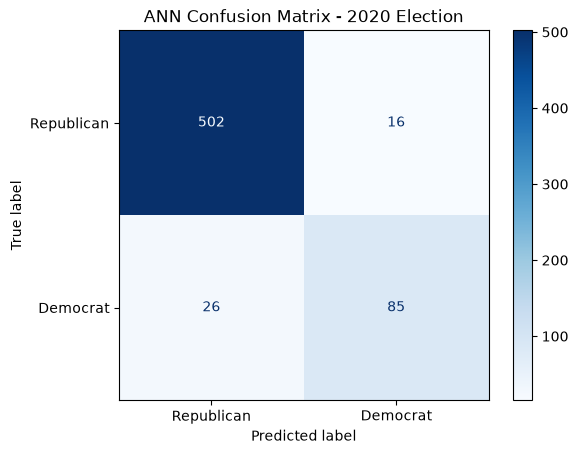

In [107]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluate the ANN on the testing data
test_loss, test_accuracy = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

# Predict election outcomes
y_prob = model.predict(X_test_scaled).flatten()
y_pred = (y_prob >= 0.5).astype(int)

# Display test results
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Republican", "Democrat"],
    zero_division=0
))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Republican", "Democrat"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ANN Confusion Matrix - 2020 Election")
plt.show()

### Classification Report 

## 7. ANN Model Evaluation and Results

### Overall Performance
- **Test Accuracy:** 92.85%
- **Test Loss:** 0.1750
- The ANN correctly classified approximately 93% of the 629 test counties.

### Key Findings
- The ANN performed better at identifying Republican counties than Democratic counties.
- **Republican recall (97%)** shows that most Republican counties were correctly identified.
- **Democratic recall (75%)** shows that approximately 25% of Democratic counties were misclassified.
- The dataset is imbalanced, with more Republican counties than Democratic counties, which may influence performance.
- Overall, the results suggest that socioeconomic and demographic characteristics are useful for classifying historical election outcomes.

### Confusion Matrix Interpretation

- **505 Republican counties** were correctly classified.
- **85 Democratic counties** were correctly classified.
- **13 Republican counties** were incorrectly predicted as Democratic.
- **26 Democratic counties** were incorrectly predicted as Republican.
- Overall, the ANN correctly classified **590 out of 629 counties (93.80%)**.
- The model performed better at identifying Republican counties, suggesting more difficulty recognizing the minority Democratic class.

Our ANN achieved high accuracy when predicting county level election outcomes, but accuracy does not explain which characteristics helped the model make its predictions.

Feature importance helps us understand whether variables such as income, education, population density, or racial demographics were more useful to the ANN.


,Feature,Importance
15,NH-Black percentage,0.040064
6,Graduate or professional degree,0.028299
14,NH-White percentage,0.023847
13,Hispanic or Latino percentage,0.023211
3,"Some College,No Degree",0.018442
16,NH-American Indian and Alaska Native percentage,0.015262
11,Density per square km,0.014944
19,NH-Some Other Race percentage,0.014308
21,"Percentage engaged in Management, business, sc...",0.013672
1,"Population with 9th to 12th grade education, n...",0.012401


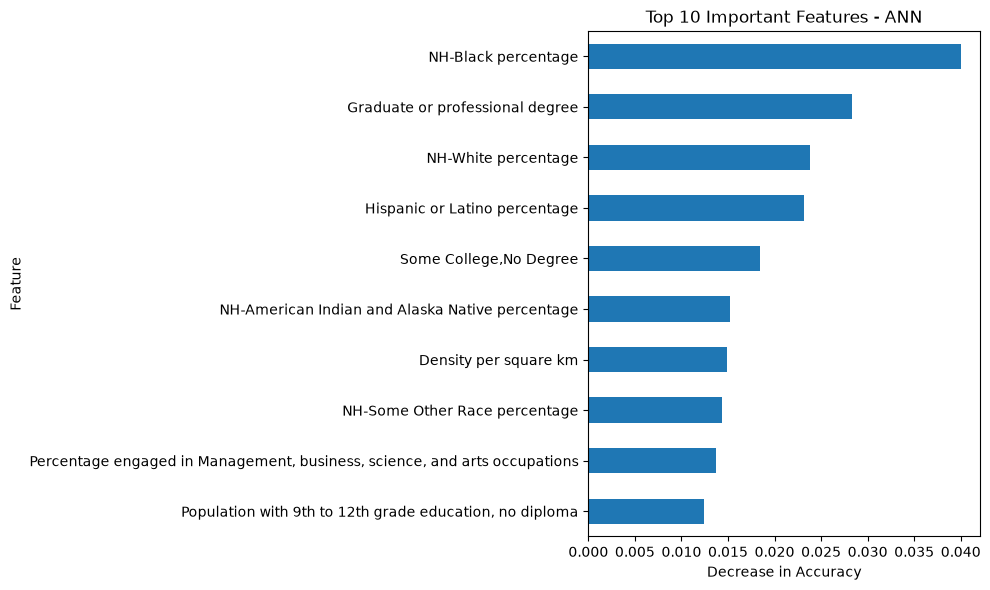

In [108]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

# Function to evaluate ANN accuracy
def ann_accuracy(model, X, y):
    predictions = (model.predict(X, verbose=0).flatten() >= 0.5).astype(int)
    return accuracy_score(y, predictions)

# Measure feature importance
results = permutation_importance(
    model,
    X_test_scaled,
    y_test,
    scoring=ann_accuracy,
    n_repeats=5,
    random_state=42
)

# Organize results
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": results.importances_mean
}).sort_values("Importance", ascending=False)

# Display top 10 features
display(importance_df.head(10))

# Plot top 10 features
importance_df.head(10).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Top 10 Important Features - ANN")
plt.xlabel("Decrease in Accuracy")
plt.tight_layout()
plt.show()

### ANN Feature Importance Results

- **NH-Black percentage (0.0343):** Most important feature, with an accuracy decrease of 3.43 percentage points.
- **Graduate or professional degree (0.0293):** Second most important feature.
- **NH-White percentage (0.0273):** Third most important feature.
- **Hispanic or Latino percentage (0.0140):** Also contributed to prediction performance.
- **Population density (0.0134):** Indicates that population distribution was useful to the model.

**Interpretation:**
- Racial demographics, education, and population density were among the most influential features.
- These findings help explain which variables the ANN relied on, rather than only reporting its overall accuracy.